# Encoder (fine-tuned multilingual transformer)

Training and prediction need a GPU: run on Kaggle with a GPU and internet on. Locally (or in a later Kaggle session with the artifacts attached as an input) every long step is loaded from `ARTIFACTS_DIR`, so the notebook runs without a GPU.

In [1]:
import sys
from pathlib import Path

# Make the repo importable: the local checkout, or a fresh clone on Kaggle/Colab. Then pin versions that must match.
REPO_URL = "https://github.com/BohdanZasymovych/ai-hw3-ai-text-detection.git"
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "setup_env.py").exists()), None)
if REPO is None:
    REPO = Path("/kaggle/working/hw3" if Path("/kaggle").exists() else "/content/hw3")
    if REPO.exists():
        !git -C {REPO} pull -q
    else:
        !git clone -q --depth 1 {REPO_URL} {REPO}
sys.path.insert(0, str(REPO))

import setup_env

setup_env.install_pins()

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer

from utils import (ARTIFACTS_DIR, DATA_DIR, ENCODER, ENV, LABEL_ORDER, SEED, artifact_dir, cached, class_report,
                   ensure_data, ensure_dirs, find_artifact, get_split, get_subsample, group_f1, macro_f1,
                   plot_confusion, plot_group_f1, submit_to_kaggle, write_submission)
from utils.encoder import head_tail_encode, predict_logits, train_encoder

ensure_dirs()
ensure_data()
split = get_split()  # fixed train/val split, made and cached on first use
gpu = f"{torch.cuda.device_count()}x {torch.cuda.get_device_name(0)}" if torch.cuda.is_available() else "none"
print(f"env={ENV}  gpu={gpu}  data={DATA_DIR}  artifacts={ARTIFACTS_DIR}")

SUBMIT = False  # True: save the test predictions and upload the submission to Kaggle (5 uploads a day)

/home/bohdan/code/ai/hw3-ai-text-detection/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/split.pkl
env=local  gpu=none  data=/home/bohdan/code/ai/hw3-ai-text-detection/data  artifacts=/home/bohdan/code/ai/hw3-ai-text-detection/artifacts


## Data

Load the fixed validation split and the fixed training subsample (the same ones all notebooks use), and the test set.

In [2]:
train_full = pd.read_csv(DATA_DIR / "train.csv")
subsample = get_subsample()
train = train_full.iloc[subsample].reset_index(drop=True)
val = train_full.iloc[split["val"]].reset_index(drop=True)
del train_full
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

pd.DataFrame({"texts": [len(train), len(val), len(test)]}, index=["train subsample", "validation", "test"])

[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/split.pkl
[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/subsample.npy


,texts
train subsample,50000
validation,27238
test,25000


## Tokenization

Most texts are longer than the 512-token limit of the encoder. A text that is too long keeps its first $128$ and its last $382$ tokens (head + tail truncation), so the input is $[\texttt{<s>}] \oplus t_{1:128} \oplus t_{n-381:n} \oplus [\texttt{</s>}]$ for a text of $n > 510$ tokens. This keeps both ends of the text in one pass per text. The token ids of each part are cached.

In [3]:
HEAD, TAIL = 128, 382  # 128 + 382 + <s> + </s> = 512 tokens
data_key = {"n_train": len(train), "n_val": len(val), "checksum": int(subsample.sum()), "v": 1}
tok_key = {**data_key, "tokenizer": ENCODER, "head": HEAD, "tail": TAIL}

tokenizer = AutoTokenizer.from_pretrained(ENCODER)
encoded = {name: cached(f"enc_ids_{name}", lambda: head_tail_encode(df["text"], tokenizer, HEAD, TAIL),
                        key={**tok_key, "part": name})
           for name, df in [("train", train), ("val", val), ("test", test)]}

pd.DataFrame({
    name: {"texts": len(e["n_tokens"]), "median tokens": np.median(e["n_tokens"]),
           "truncated, %": (e["n_tokens"] > HEAD + TAIL).mean() * 100}
    for name, e in encoded.items()
}).T.style.format({"texts": "{:,.0f}", "median tokens": "{:,.0f}", "truncated, %": "{:.1f}%"})

[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/enc_ids_train.pkl
[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/enc_ids_val.pkl
[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/enc_ids_test.pkl


,texts,median tokens,"truncated, %"
train,"50,000",685,65.4%
val,"27,238",663,63.8%
test,"25,000",658,61.5%


## Training

Fine-tune the encoder on the training subsample: AdamW, learning rate $2 \cdot 10^{-5}$ with 10% linear warmup and linear decay, 2 epochs, batch 16, fp16, no class weights. The model is saved to `ARTIFACTS_DIR` and training is skipped when a saved run with the same settings exists. Left: training loss averaged over every 50 steps. Right: validation macro-F1 after each epoch, used only to check whether more epochs would help; the reported model is always the one after the last epoch.

[cache] key changed, clearing /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/encoder
[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/encoder_history.json


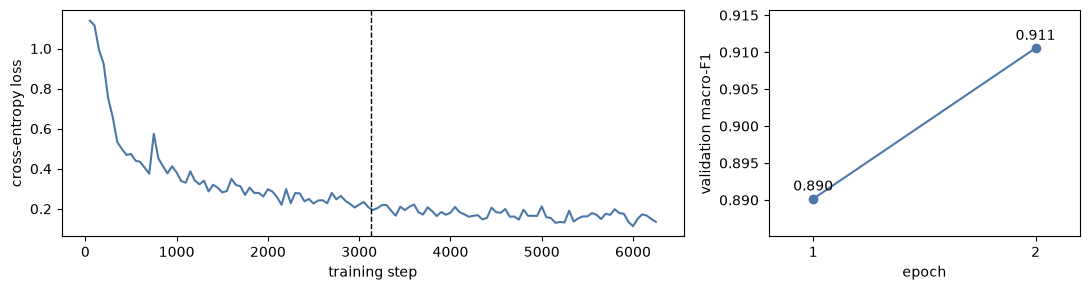

In [4]:
TRAIN = {"lr": 2e-5, "epochs": 2, "batch_size": 16, "warmup": 0.1, "weight_decay": 0.01, "seed": SEED}
KEY = {**tok_key, "backbone": ENCODER, **TRAIN, "v": 2}
label_order = np.array(LABEL_ORDER)
y_train = train["label"].map({label: i for i, label in enumerate(LABEL_ORDER)}).to_numpy()

model_dir = artifact_dir("encoder", key=KEY)
history = cached("encoder_history", lambda: train_encoder(
    ENCODER, encoded["train"]["ids"], y_train, model_dir,
    val_ids=encoded["val"]["ids"], val_labels=val["label"].to_numpy(), **TRAIN), key=KEY, kind="json")

loss, per_epoch = pd.DataFrame(history["loss"]), pd.DataFrame(history["val"])
fig, (ax_loss, ax_f1) = plt.subplots(1, 2, figsize=(11, 3), gridspec_kw={"width_ratios": [2, 1]})
ax_loss.plot(loss["step"], loss["loss"], color="#4C78A8")
for step in per_epoch["step"].iloc[:-1]:
    ax_loss.axvline(step, color="black", ls="--", lw=1)  # end of an epoch
ax_loss.set_xlabel("training step")
ax_loss.set_ylabel("cross-entropy loss")
ax_f1.plot(per_epoch["epoch"], per_epoch["macro_f1"], marker="o", color="#4C78A8")
for epoch, f1 in zip(per_epoch["epoch"], per_epoch["macro_f1"]):
    ax_f1.annotate(f"{f1:.3f}", (epoch, f1), textcoords="offset points", xytext=(0, 6), ha="center")
ax_f1.margins(x=0.2, y=0.25)  # room for the value labels
ax_f1.set_xticks(per_epoch["epoch"])
ax_f1.set_xlabel("epoch")
ax_f1.set_ylabel("validation macro-F1")
plt.tight_layout()
plt.show()

## Evaluation

Predict the validation set (logits cached) and show the per-class scores.

In [5]:
val_logits = cached("encoder_val_logits", lambda: predict_logits(model_dir, encoded["val"]["ids"]), key=KEY, kind="npy")
val_pred = label_order[val_logits.argmax(axis=1)]
cached("encoder_val_metrics", lambda: {"macro_f1": macro_f1(val["label"], val_pred)}, key=KEY, kind="json")
class_report(val["label"], val_pred).style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}", "support": "{:,.0f}"})

[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/encoder_val_logits.npy
[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/encoder_val_metrics.json


,precision,recall,f1,support
human,0.889,0.820,0.853,"6,675"
ai,0.987,0.996,0.991,"12,194"
fusion,0.867,0.909,0.887,"8,369"
macro avg,0.914,0.908,0.911,"27,238"


Confusion matrix. Colours show the share of each true class; the counts are in brackets.

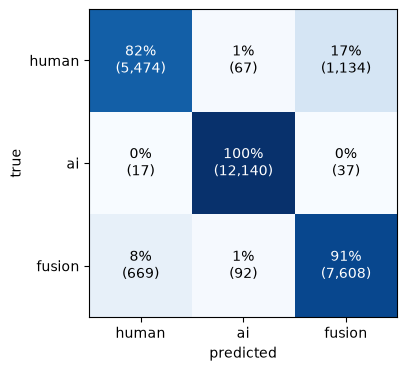

In [6]:
fig, ax = plt.subplots(figsize=(4.5, 4))
plot_confusion(val["label"], val_pred, ax)
plt.show()

Macro-F1 per language and domain. The dashed line is the overall validation macro-F1.

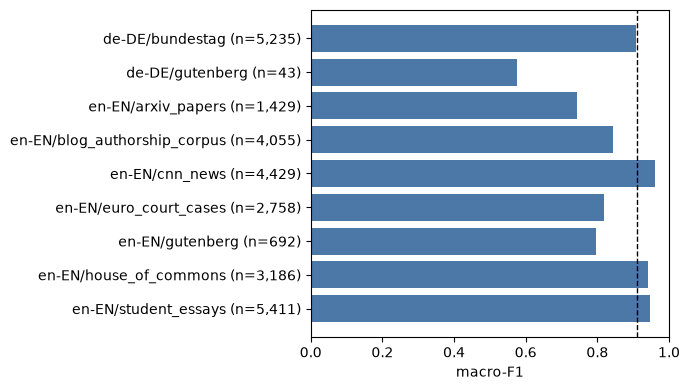

In [7]:
by_group = group_f1(val, val_pred, ["lang", "domain"])
fig, ax = plt.subplots(figsize=(7, 4))
plot_group_f1(by_group, macro_f1(val["label"], val_pred), ax)
plt.tight_layout()
plt.show()

## Comparison with Baseline

F1 per class and macro-F1 of TF-IDF 50k (validation scores saved by `02_baseline`) and XLM-R base 50k, on the same validation rows. If the TF-IDF scores are not found (e.g. on Kaggle without the local artifacts attached), only XLM-R base 50k is shown.

In [8]:
preds = {}
baseline_path = find_artifact("baseline_val_scores", kind="npy")
if baseline_path is not None:
    baseline_key = json.loads(baseline_path.with_suffix(".key.json").read_text())
    assert baseline_key["checksum"] == data_key["checksum"], "baseline used a different split/subsample"
    baseline_scores = np.load(baseline_path)
    preds["TF-IDF 50k"] = label_order[baseline_scores.argmax(axis=1)]
else:
    print("baseline_val_scores.npy not found: run 02_baseline or attach its artifacts")
preds["XLM-R base 50k"] = val_pred
MODEL_COLORS = {"TF-IDF 50k": "#9D9D9D", "XLM-R base 50k": "#4C78A8"}

pd.DataFrame({name: class_report(val["label"], pred)["f1"] for name, pred in preds.items()}).style \
    .background_gradient(cmap="Blues", axis=None).format("{:.3f}")

,TF-IDF 50k,XLM-R base 50k
human,0.807,0.853
ai,0.985,0.991
fusion,0.815,0.887
macro avg,0.869,0.911


Macro-F1 per language and domain for both models.

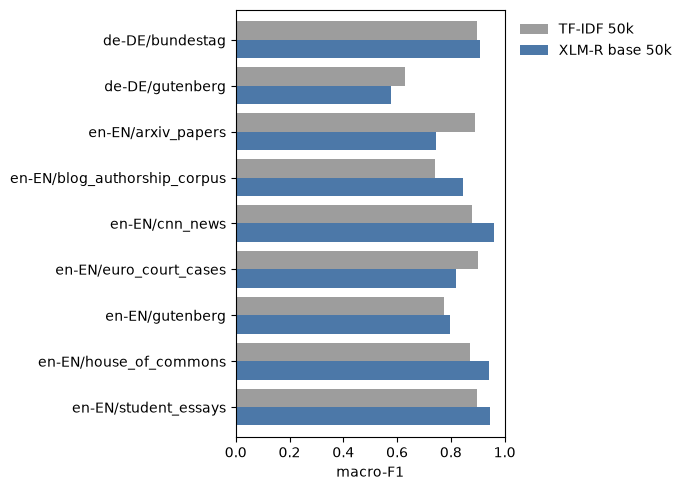

In [9]:
per_group = pd.DataFrame({name: group_f1(val, pred, ["lang", "domain"])["macro_f1"] for name, pred in preds.items()})
per_group.index = ["/".join(k) for k in per_group.index]
fig, ax = plt.subplots(figsize=(7, 5))
per_group.plot.barh(ax=ax, color=MODEL_COLORS, width=0.8)
ax.set_xlim(0, 1)
ax.set_xlabel("macro-F1")
ax.invert_yaxis()
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## Submission

Test logits are always predicted and cached, so later notebooks (ensembles, thresholds) need no GPU. Only when `SUBMIT` is True, save a valid submission file and upload it to Kaggle. The upload is cached by the run settings, so rerunning the notebook does not spend another daily submission.

In [10]:
test_logits = cached("encoder_test_logits", lambda: predict_logits(model_dir, encoded["test"]["ids"]), key=KEY, kind="npy")
test_pred = label_order[test_logits.argmax(axis=1)]

if SUBMIT:
    path = write_submission(test["id"], test_pred, sample_submission, "encoder")
    message = f"encoder: {ENCODER} head {HEAD} + tail {TAIL}, val macro-F1 {macro_f1(val['label'], val_pred):.3f}"
    cached("encoder_upload", lambda: submit_to_kaggle(path, message), key=KEY, kind="json")
    display(pd.Series(test_pred).value_counts(normalize=True).reindex(LABEL_ORDER).mul(100).round(1)
            .to_frame("share of test predictions, %").T)
else:
    print("SUBMIT is False: upload skipped")

[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/encoder_test_logits.npy
SUBMIT is False: upload skipped


## Conclusions

- **XLM-R base 50k: 0.911** macro-F1 vs 0.870 for TF-IDF 50k, better on every class; epoch 2 still added about 2 points (0.890 → 0.911).
- About 64% of the texts are longer than 512 tokens, and on the longest domains the encoder is worse than TF-IDF (arXiv 0.744 vs 0.891, court cases 0.820 vs 0.900): head + tail truncation drops the middle of long texts.
- In the final pipeline this model is used through its window scores (group C, 04); the same recipe, scaled to the large backbone, 100k texts and 3 epochs, gives the main encoder (06).